# Capstone EDA: quarterly company financials

**Question:** using what a company reported up to the end of a quarter, can I predict its **revenue** and **profit margin** for the next quarter?

- **Who uses it:** an analyst who wants an early estimate before the next quarterly report is published.
- **One row:** one company in one quarter (`cik` + `period_end`).
- **Targets:** next quarter revenue (in log) and next quarter profit margin (net income / revenue). 
- **When the prediction is made:** right after quarter *t* is reported. Only values from quarter *t* or earlier can be features.

Data: quarterly figures from SEC filings (10-Q and 10-K) for 400 US listed companies, 2018 to 2026. Source: SEC EDGAR Company Facts API, https://www.sec.gov/search-filings/edgar-application-programming-interfaces. File built on 9 November 2026.

## 1. Setup

Imports, one seed, file paths and the start.....

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

DATA_URL = "kvartalni_podaci (2).csv"   # the file sits in this location
ID_COLS = ["cik", "period_end"]
TARGETS = ["log_revenue_next", "profit_margin_next"]
TEST_START = "2025-01-01"   # quarters ending on or after this date are the test set

FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.4


## 2. Load and first look

Load the file and take a first look. `raw` stays untouched, I work on `df`. 13,966 rows and 66 columns. `revenue` and the dates are loaded as text.

In [ ]:
raw = pd.read_csv(DATA_URL)
df = raw.copy()
df.columns = df.columns.str.strip()

print(df.shape)
df.info()
df.sample(5, random_state=SEED)

(13966, 66)
<class 'pandas.DataFrame'>
RangeIndex: 13966 entries, 0 to 13965
Data columns (total 66 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cik                          13966 non-null  int64  
 1   ticker                       13966 non-null  str    
 2   company                      13966 non-null  str    
 3   period_start                 13966 non-null  str    
 4   period_end                   13966 non-null  str    
 5   calendar_year                13966 non-null  int64  
 6   calendar_quarter             13966 non-null  int64  
 7   revenue                      13592 non-null  str    
 8   cost_of_revenue              8778 non-null   float64
 9   gross_profit                 5912 non-null   float64
 10  operating_income             10847 non-null  float64
 11  net_income                   13966 non-null  float64
 12  pretax_income                13002 non-null  float64
 13  income_tax_expe

,cik,ticker,company,period_start,period_end,calendar_year,calendar_quarter,revenue,cost_of_revenue,gross_profit,operating_income,net_income,pretax_income,income_tax_expense,research_development,selling_general_admin,operating_expenses,interest_expense,eps_basic,eps_diluted,shares_basic,shares_diluted,assets,current_assets,noncurrent_assets,liabilities,current_liabilities,noncurrent_liabilities,equity,equity_including_minority,liabilities_and_equity,cash,cash_restricted,receivables,inventory,ppe_net,goodwill,intangibles_net,accounts_payable,retained_earnings,treasury_stock,short_term_borrowings,long_term_debt_current,long_term_debt_noncurrent,deferred_revenue_current,operating_cash_flow,investing_cash_flow,financing_cash_flow,capex,acquisitions_cash,depreciation_amortization,stock_compensation,dividends_paid,share_repurchases,debt_repayments,debt_issued,income_taxes_paid,interest_paid,dividend_per_share,shares_outstanding,revenue_concept,net_income_method,core_available,balance_identity_difference,balance_identity_status,free_cash_flow
8568,1579241,ALLE,Allegion plc,10/1/2020,12/31/2020,2020,4,"727,300,000.00",4.074000e+08,NaN,117700000.0,9.330000e+07,1.058000e+08,1.240000e+07,NaN,1.615000e+08,NaN,12300000.0,NaN,NaN,NaN,NaN,3.069400e+09,1.145000e+09,NaN,2.236800e+09,5.215000e+08,NaN,8.294000e+08,8.326000e+08,3.069400e+09,4.804000e+08,4.804000e+08,NaN,2.831000e+08,2.949000e+08,8.190000e+08,3.688000e+08,2.204000e+08,9.856000e+08,NaN,NaN,NaN,1.429400e+09,NaN,2.009000e+08,-1.740000e+07,-1.426000e+08,NaN,NaN,2.070000e+07,NaN,2.900000e+07,1.147000e+08,1.000000e+05,NaN,NaN,NaN,NaN,91212741.0,RevenueFromContractWithCustomerExcludingAssess...,cumulative_difference_cross_filing,1,0.0,pass,NaN
339,318154,AMGN,Amgen Inc.,1/1/2024,3/31/2024,2024,1,"7,447,000,000.00",3.200000e+09,NaN,991000000.0,-1.130000e+08,-6.800000e+07,4.500000e+07,NaN,1.808000e+09,NaN,NaN,-0.21,-0.21,5.360000e+08,5.360000e+08,9.298000e+10,2.802900e+10,NaN,NaN,1.971400e+10,NaN,5.022000e+09,NaN,9.298000e+10,9.708000e+09,9.708000e+09,6.776000e+09,8.724000e+09,6.002000e+09,1.857000e+10,3.022200e+10,1.628000e+09,-2.787000e+10,NaN,NaN,3.959000e+09,6.006100e+10,NaN,6.890000e+08,-2.170000e+08,-1.708000e+09,230000000.0,NaN,1.399000e+09,103000000.0,1.208000e+09,NaN,0.000000e+00,0.000000e+00,NaN,NaN,2.25,536400000.0,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,459000000.0
795,93410,CVX,Chevron Corp,4/1/2024,6/30/2024,2024,2,"49,574,000,000.00",3.086700e+10,NaN,NaN,4.434000e+09,7.036000e+09,2.593000e+09,NaN,1.048000e+09,NaN,NaN,2.43,2.43,1.825842e+09,1.833431e+09,2.606440e+11,3.936900e+10,NaN,1.003810e+11,3.402700e+10,NaN,1.592330e+11,1.602630e+11,2.606440e+11,4.008000e+09,4.965000e+09,1.830000e+10,1.047700e+10,NaN,4.722000e+09,NaN,2.100700e+10,2.039600e+11,NaN,1.735000e+09,NaN,NaN,NaN,6.295000e+09,-3.954000e+09,-4.565000e+09,NaN,0.0,4.004000e+09,NaN,2.978000e+09,3.001000e+09,NaN,1.000000e+08,NaN,182000000.0,1.63,NaN,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,NaN
8872,37996,F,Ford Motor Co,1/1/2018,3/31/2018,2018,1,"41,959,000,000.00",3.575300e+10,NaN,NaN,1.745000e+09,1.919000e+09,1.740000e+08,NaN,2.747000e+09,NaN,NaN,0.44,0.43,3.974000e+09,3.997000e+09,2.672300e+11,1.232640e+11,NaN,2.306960e+11,9.987800e+10,NaN,3.640000e+10,3.643600e+10,2.672300e+11,1.794000e+10,1.813700e+10,1.238600e+10,1.237100e+10,3.611800e+10,2.740000e+08,NaN,NaN,2.252900e+10,1.342000e+09,NaN,NaN,NaN,2.336000e+09,3.514000e+09,-6.544000e+09,2.414000e+09,NaN,NaN,NaN,NaN,1.113000e+09,8.900000e+07,1.236000e+10,1.695300e+10,NaN,NaN,0.28,NaN,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,NaN
11744,866787,AZO,"AutoZone, Inc.",8/30/2020,11/21/2020,2020,4,"3,154,261,000.00",1.478644e+09,1.675617e+09,615225000.0,4.424330e+08,5.690460e+08,1.266130e+08,NaN,1.060392e+09,NaN,NaN,19.05,18.61,2.322300e+07,2.377800e+07,1.456857e+10,6.836795e+09,NaN,NaN,6.456703e+09,NaN,-1.026980e+09,NaN,1.456857e+10,1.664005e+09,NaN,3.509150e+08,NaN,4.586002e+09,3.02645

Revenue is in text needs to be numeric

In [ ]:

print(df["revenue"].head(3).tolist())
print(df.loc[df["revenue"].str.contains(r"\(", na=False), "revenue"].head(3).tolist())
print("values in brackets:", df["revenue"].str.contains(r"\(", na=False).sum())
print("just a dash:", (df["revenue"].str.strip() == "-").sum())

[' 61,137,000,000.00 ', ' 53,265,000,000.00 ', ' 62,900,000,000.00 ']
[' (3,544,000,000.00)', ' (3,858,000,000.00)', ' (866,000,000.00)']
values in brackets: 35
just a dash: 3


## 3. Data dictionary and missingness

Type, unique values and missing share of every column. The key `cik` + `period_end` is unique. Many columns are missing in 40% or more of the rows, so I keep only the ones almost every company reports.

In [ ]:
meaning = {
    "cik": "SEC company id",
    "ticker": "stock ticker",
    "company": "company name",
    "period_end": "last day of the quarter",
    "calendar_year": "calendar year of the quarter",
    "calendar_quarter": "calendar quarter 1-4",
    "revenue": "revenue in the quarter, USD",
    "net_income": "net income in the quarter, USD",
    "operating_cash_flow": "cash flow from operations, USD",
    "assets": "total assets at quarter end, USD",
    "equity": "shareholders equity at quarter end, USD",
    "cash": "cash at quarter end, USD",
}

data_dict = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})
data_dict["meaning"] = data_dict.index.map(meaning).fillna("")

assert not df.duplicated(ID_COLS).any()
print("quarters per company:", df.groupby("cik").size().min(), "to", df.groupby("cik").size().max())

data_dict.sort_values("pct_missing", ascending=False)

quarters per company: 34 to 35


,dtype,n_unique,n_missing,pct_missing,meaning
noncurrent_assets,float64,703,13263,95.0,
noncurrent_liabilities,float64,1591,12371,88.6,
operating_expenses,float64,2804,10987,78.7,
short_term_borrowings,float64,2151,10692,76.6,
research_development,float64,2761,10269,73.5,
debt_issued,float64,2025,9134,65.4,
long_term_debt_current,float64,2999,8839,63.3,
income_taxes_paid,float64,3096,8685,62.2,
debt_repayments,float64,2460,8289,59.4,
gross_profit,float64,5282,8054,57.7,


Who is missing revenue (2.7% of rows)? Mostly banks.

In [ ]:
# who is missing revenue?
df[df["revenue"].isna()]["company"].value_counts().head(8)

company
The Goldman Sachs Group, Inc.              35
JPMORGAN CHASE & CO                        35
TRUIST FINANCIAL CORPORATION               35
SYNCHRONY FINANCIAL                        35
MORGAN STANLEY                             34
Regions Financial Corporation              34
THE BANK OF NEW YORK MELLON CORPORATION    33
XCEL ENERGY INC                            28
Name: count, dtype: int64

## 4. Clean

One function does all the cleaning, so I can re-run it on a new download:

- revenue to number; negative revenue (35 rows) set to missing
- calendar quarter from the middle of the period, not from the last day
- profit margin = net income / revenue; margins outside -100% to +100% (571 rows, mostly REITs and banks with incomplete revenue) set to missing
- features: log revenue, log assets, equity/assets, cash/assets, operating cash flow/revenue, revenue growth vs previous quarter and vs last year
- targets: next quarter log revenue and margin, with `shift(-1)` per company

No imputing or scaling here.

In [ ]:
KEEP = ["cik", "ticker", "company", "period_end", "calendar_year", "calendar_quarter",
        "revenue", "net_income", "operating_cash_flow", "assets", "equity", "cash"]

def clean_data(d):
    d = d.copy()
    d.columns = d.columns.str.strip()
    d = d.drop_duplicates()
    d["company"] = d["company"].str.replace("\xa0", " ", regex=False).str.strip()

    # revenue: " 61,137,000,000.00 " -> 61137000000.0 , "(866,000,000.00)" -> negative
    rev = d["revenue"].astype(str).str.strip().str.replace(",", "", regex=False)
    rev = rev.str.replace("(", "-", regex=False).str.replace(")", "", regex=False)
    d["revenue"] = pd.to_numeric(rev, errors="coerce")
    not_positive = d["revenue"] <= 0
    d.loc[not_positive, "revenue"] = np.nan

    d["period_start"] = pd.to_datetime(d["period_start"], format="%m/%d/%Y")
    d["period_end"] = pd.to_datetime(d["period_end"], format="%m/%d/%Y")

    # calendar quarter from the middle of the period, not from the last day
    # (a quarter that ends on 1 July is a Q2, not a Q3)
    middle = d["period_start"] + (d["period_end"] - d["period_start"]) / 2
    d["calendar_year"] = middle.dt.year
    d["calendar_quarter"] = middle.dt.quarter

    d = d[KEEP].sort_values(["cik", "period_end"])

    d = d.assign(
        profit_margin=d["net_income"] / d["revenue"],
        log_revenue=np.log(d["revenue"]),
        log_assets=np.log(d["assets"]),
        equity_ratio=d["equity"] / d["assets"],
        cash_ratio=d["cash"] / d["assets"],
        ocf_margin=d["operating_cash_flow"] / d["revenue"],
    )

    # revenue is not reliable in these rows
    bad = d["profit_margin"].abs() > 1
    d.loc[bad, ["profit_margin", "log_revenue", "ocf_margin"]] = np.nan

    # shift before dropping rows, so shift(1) is always the previous quarter of that company
    by_company = d.groupby("cik")
    d["revenue_growth_qoq"] = d["log_revenue"] - by_company["log_revenue"].shift(1)
    d["revenue_growth_yoy"] = d["log_revenue"] - by_company["log_revenue"].shift(4)
    d["log_revenue_next"] = by_company["log_revenue"].shift(-1)
    d["profit_margin_next"] = by_company["profit_margin"].shift(-1)

    print("revenue <= 0 set to missing:", not_positive.sum())
    print("margin outside -1..1 set to missing:", bad.sum())
    print("same company twice in one calendar quarter:",
          d.duplicated(["cik", "calendar_year", "calendar_quarter"]).sum(), "rows")

    d = d.dropna(subset=["log_revenue", "profit_margin"] + TARGETS)
    return d.reset_index(drop=True)

df = clean_data(raw)

assert not df.duplicated(ID_COLS).any()
assert df["profit_margin"].between(-1, 1).all()

print("rows:", len(raw), "->", len(df))
print("companies:", raw["cik"].nunique(), "->", df["cik"].nunique())
df.head()

revenue <= 0 set to missing: 35
margin outside -1..1 set to missing: 571
same company twice in one calendar quarter: 24 rows
rows: 13966 -> 12444
companies: 400 -> 387


,cik,ticker,company,period_end,calendar_year,calendar_quarter,revenue,net_income,operating_cash_flow,assets,equity,cash,profit_margin,log_revenue,log_assets,equity_ratio,cash_ratio,ocf_margin,revenue_growth_qoq,revenue_growth_yoy,log_revenue_next,profit_margin_next
0,1800,ABT,ABBOTT LABORATORIES,2018-03-31,2018,1,7.390000e+09,418000000.0,1.108000e+09,7.090800e+10,3.139900e+10,3.857000e+09,0.056563,22.723394,24.984649,0.442813,0.054394,0.149932,NaN,NaN,22.773150,0.094374
1,1800,ABT,ABBOTT LABORATORIES,2018-06-30,2018,2,7.767000e+09,733000000.0,1.244000e+09,6.841500e+10,3.057700e+10,3.065000e+09,0.094374,22.773150,24.948858,0.446934,0.044800,0.160165,0.049756,NaN,22.758755,0.073537
2,1800,ABT,ABBOTT LABORATORIES,2018-09-30,2018,3,7.656000e+09,563000000.0,2.183000e+09,7.163700e+10,3.070500e+10,7.369000e+09,0.073537,22.758755,24.994878,0.428619,0.102866,0.285136,-0.014394,NaN,22.772892,0.084224
3,1800,ABT,ABBOTT LABORATORIES,2018-12-31,2018,4,7.765000e+09,654000000.0,1.765000e+09,6.717300e+10,3.052400e+10,3.844000e+09,0.084224,22.772892,24.930537,0.454409,0.057225,0.227302,0.014137,NaN,22.742825,0.089184
4,1800,ABT,ABBOTT LABORATORIES,2019-03-31,2019,1,7.535000e+09,672000000.0,7.120000e+08,6.761000e+10,3.092500e+10,3.022000e+09,0.089184,22.742825,24.937022,0.457403,0.044698,0.094492,-0.030068,0.019431,22.800079,0.126081


### Split before looking

Split by time before any EDA: train = quarters ending before 2025, test = 2025 and later (about 18% of rows). From here on every chart and statistic uses train only.

In [ ]:
train = df[df["period_end"] < TEST_START].copy()
test = df[df["period_end"] >= TEST_START].copy()

assert train["period_end"].max() < test["period_end"].min()
print("train:", train.shape, "|", train["period_end"].min().date(), "to", train["period_end"].max().date())
print("test: ", test.shape, "|", test["period_end"].min().date(), "to", test["period_end"].max().date())
print("test share:", round(len(test) / len(df), 3))

train: (10256, 22) | 2018-01-26 to 2024-12-31
test:  (2188, 22) | 2025-01-24 to 2026-07-05
test share: 0.176


## 5. Univariate EDA

Raw revenue is extremely right skewed (a few giants). Log revenue is close to symmetric, so I model log revenue.

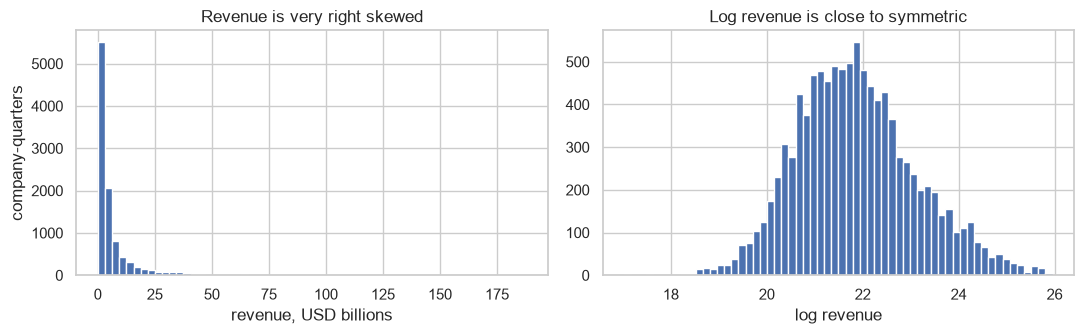

In [ ]:
num_cols = ["log_revenue", "profit_margin", "revenue_growth_qoq", "revenue_growth_yoy",
            "log_assets", "equity_ratio", "cash_ratio", "ocf_margin"]
cat_cols = ["calendar_quarter"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
(train["revenue"] / 1e9).hist(bins=60, ax=ax[0])
ax[0].set_title("Revenue is very right skewed")
ax[0].set_xlabel("revenue, USD billions")
ax[0].set_ylabel("company-quarters")
train["log_revenue"].hist(bins=60, ax=ax[1])
ax[1].set_title("Log revenue is close to symmetric")
ax[1].set_xlabel("log revenue")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_revenue_raw_vs_log.png", dpi=120)
plt.show()

Distribution of every numeric feature. Margin is centred around 12%, growth vs previous quarter near +2%. `ocf_margin` and `equity_ratio` have a few extreme values. Because of the skew I report medians.

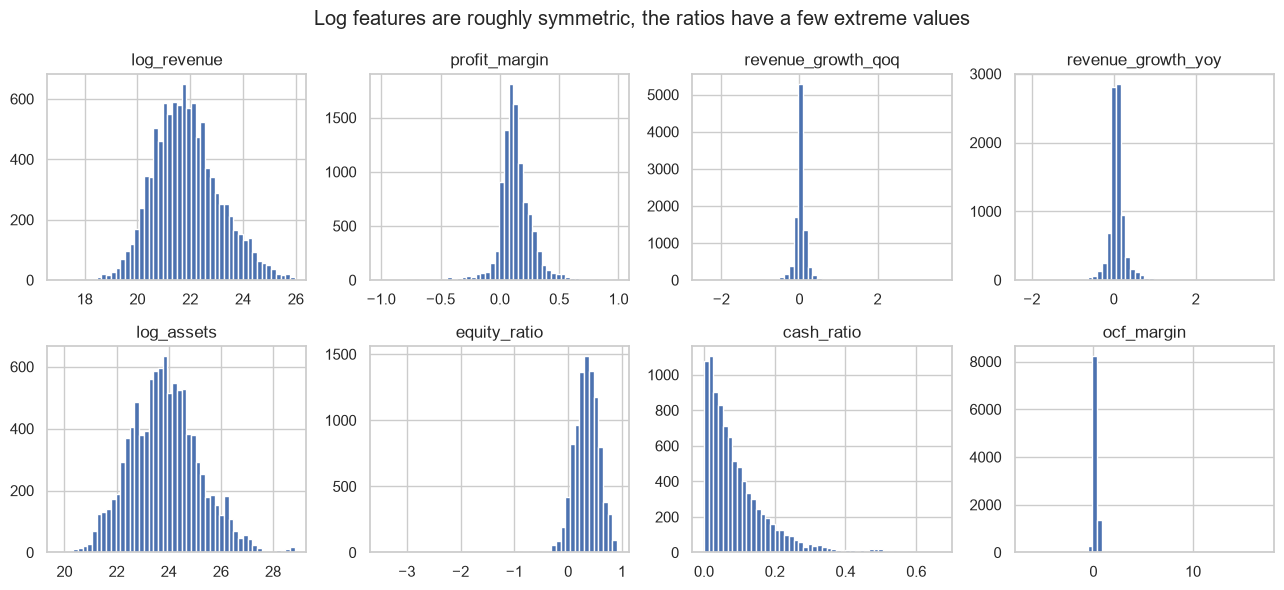

,count,mean,std,min,25%,50%,75%,max
log_revenue,10256.0,21.860,1.255,17.027,20.985,21.777,22.606,25.959
profit_margin,10256.0,0.130,0.155,-0.998,0.060,0.119,0.196,0.990
revenue_growth_qoq,9755.0,0.021,0.202,-2.443,-0.029,0.021,0.075,3.592
revenue_growth_yoy,8655.0,0.076,0.249,-2.129,-0.003,0.065,0.144,3.623
log_assets,10256.0,23.853,1.313,19.789,22.909,23.809,24.664,28.832
equity_ratio,9598.0,0.327,0.295,-3.471,0.194,0.348,0.497,0.913
cash_ratio,9116.0,0.093,0.092,0.000,0.028,0.065,0.126,0.666
ocf_margin,10068.0,0.231,0.424,-6.711,0.098,0.195,0.307,16.948


In [ ]:
train[num_cols].hist(bins=50, figsize=(13, 6), layout=(2, 4))
plt.suptitle("Log features are roughly symmetric, the ratios have a few extreme values")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_features.png", dpi=120)
plt.show()

train[num_cols].describe().T.round(3)

Rows per quarter are balanced. About 9% of rows are loss quarters.

In [ ]:
print(train["calendar_quarter"].value_counts().sort_index())
print("share of loss quarters:", round((train["profit_margin"] < 0).mean(), 3))

calendar_quarter
1    2593
2    2559
3    2547
4    2557
Name: count, dtype: int64
share of loss quarters: 0.087


## 6. Targets and relationships

Both targets look like their current quarter versions: the same variable one quarter later.

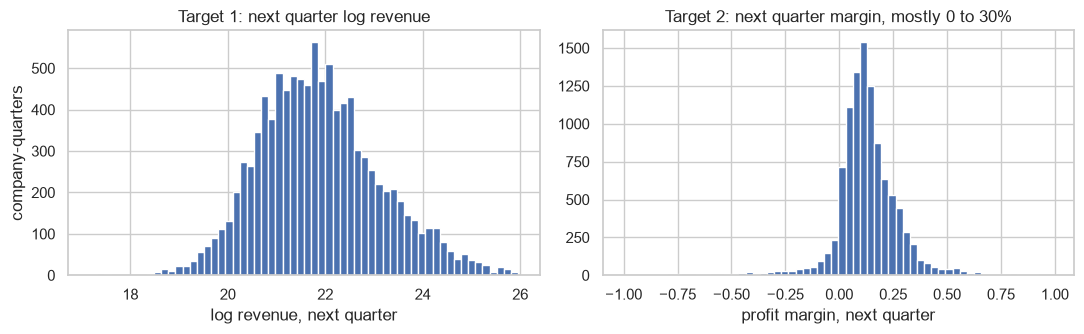

,count,mean,std,min,25%,50%,75%,max
log_revenue_next,10256.0,21.879,1.248,17.168,21.003,21.794,22.619,25.959
profit_margin_next,10256.0,0.130,0.155,-0.998,0.060,0.119,0.196,0.990


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train["log_revenue_next"].hist(bins=60, ax=ax[0])
ax[0].set_title("Target 1: next quarter log revenue")
ax[0].set_xlabel("log revenue, next quarter")
ax[0].set_ylabel("company-quarters")
train["profit_margin_next"].hist(bins=60, ax=ax[1])
ax[1].set_title("Target 2: next quarter margin, mostly 0 to 30%")
ax[1].set_xlabel("profit margin, next quarter")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_targets.png", dpi=120)
plt.show()

train[TARGETS].describe().T.round(3)

Target vs the same variable this quarter. Revenue is almost on the diagonal, margin is much noisier, so margin is the harder target.

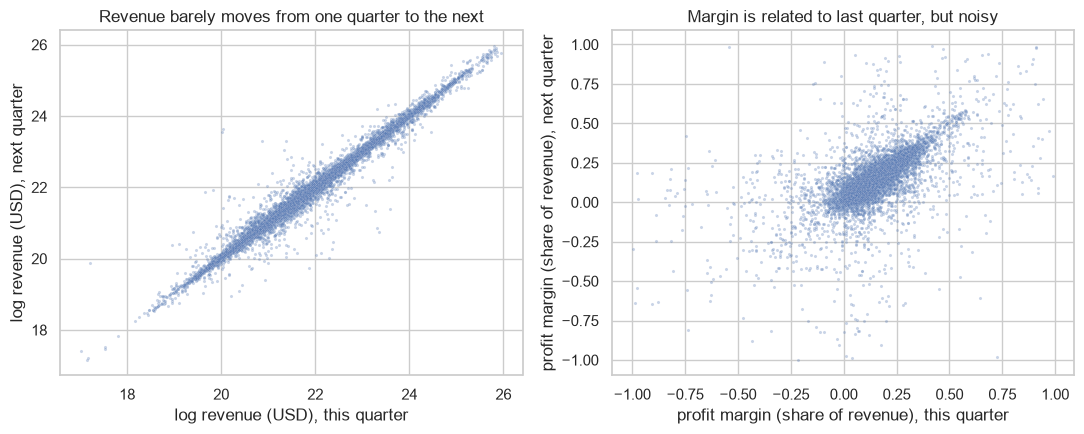

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(data=train, x="log_revenue", y="log_revenue_next", s=5, alpha=0.3, ax=ax[0])
ax[0].set_title("Revenue barely moves from one quarter to the next")
ax[0].set_xlabel("log revenue (USD), this quarter")
ax[0].set_ylabel("log revenue (USD), next quarter")
sns.scatterplot(data=train, x="profit_margin", y="profit_margin_next", s=5, alpha=0.3, ax=ax[1])
ax[1].set_title("Margin is related to last quarter, but noisy")
ax[1].set_xlabel("profit margin (share of revenue), this quarter")
ax[1].set_ylabel("profit margin (share of revenue), next quarter")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_target_vs_current.png", dpi=120)
plt.show()

Correlation of each feature with the targets: 0.99 for revenue with next revenue, 0.59 for margin with next margin, 0.28 for operating cash flow margin with next margin. Growth features are weak. These are associations, not causes.

In [ ]:
corr_target = train[num_cols + TARGETS].corr()[TARGETS].drop(TARGETS)
corr_target.sort_values("profit_margin_next", key=abs, ascending=False).round(2)

,log_revenue_next,profit_margin_next
profit_margin,-0.10,0.59
ocf_margin,-0.15,0.28
log_revenue,0.99,-0.10
revenue_growth_yoy,-0.01,0.08
log_assets,0.76,0.06
cash_ratio,-0.15,0.04
revenue_growth_qoq,0.00,0.03
equity_ratio,-0.13,0.03


Seasonality: median revenue growth is about -0.7% in Q1 and +2% to +4% in the other quarters. For margin the quarter makes almost no difference.

In [ ]:
train.groupby("calendar_quarter")[["revenue_growth_qoq", "profit_margin_next"]].median().round(3)

,revenue_growth_qoq,profit_margin_next
calendar_quarter,,
1,-0.007,0.119
2,0.037,0.124
3,0.021,0.118
4,0.025,0.116


## 7. Correlation, redundancy and leakage check

Correlation between all features, and a leakage check. `log_revenue` and `log_assets` move together (both measure size). The only feature above 0.9 with a target is `log_revenue`. That is not leakage: this quarter's revenue is known when the prediction is made. It does mean R² will look great for any model, so I will compare against the "same as last quarter" baseline.

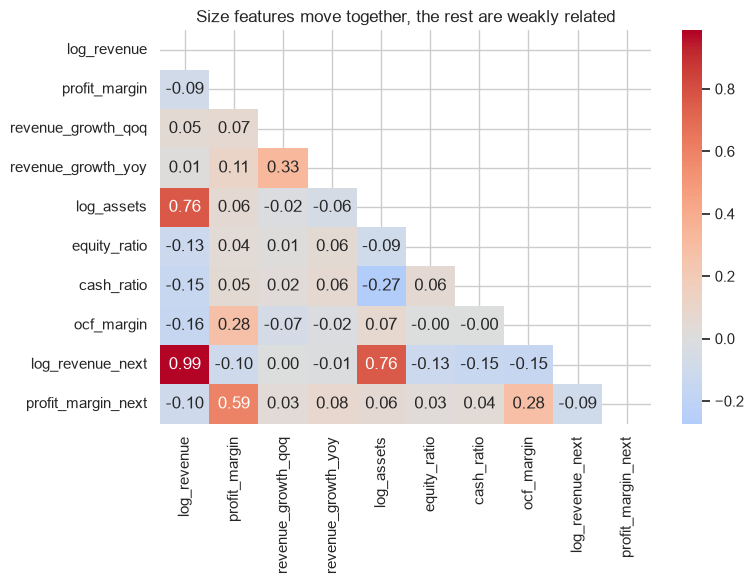

log_revenue_next -> features with |r| > 0.9: ['log_revenue']
profit_margin_next -> features with |r| > 0.9: []


In [ ]:
corr = train[num_cols + TARGETS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Size features move together, the rest are weakly related")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_correlation.png", dpi=120)
plt.show()

for target in TARGETS:
    c = corr[target].drop(TARGETS).abs()
    print(target, "-> features with |r| > 0.9:", c[c > 0.9].index.tolist())

## 8. Save outputs and record decisions

Save the clean table and the list of decisions to `outputs/` for the modelling notebook.

In [ ]:
split = np.where(df["period_end"] < TEST_START, "train", "test")
df.assign(split=split).to_csv(OUT_DIR / "clean.csv", index=False)

decisions = pd.DataFrame([
    ("grain", "one row = one company in one quarter, key cik + period_end"),
    ("targets", "next quarter log revenue and next quarter profit margin, built with shift(-1) per company"),
    ("columns", "kept only columns reported by almost all companies; dropped the ones missing 40%+"),
    ("revenue parsing", "text to number; brackets = negative; dash = missing"),
    ("negative revenue", "35 rows set to missing, not plausible"),
    ("margin outside -1..1", "571 rows set to missing; revenue tag incomplete for REITs and banks"),
    ("calendar quarter", "taken from the middle of the period, not from the last day"),
    ("log transform", "revenue and assets are very right skewed"),
    ("missing values", "median imputation + missing flag inside the pipeline, not before the split"),
    ("split", "by time: train before 2025, test 2025 and later; split before EDA, EDA on train only"),
    ("cross-validation", "GroupKFold by company"),
    ("metric", "MAE; R2 is misleading for revenue because of persistence"),
    ("baseline to beat", "naive: next quarter = this quarter"),
], columns=["step", "decision"])
decisions.to_csv(OUT_DIR / "decisions.csv", index=False)
decisions

,step,decision
0,grain,"one row = one company in one quarter, key cik ..."
1,targets,next quarter log revenue and next quarter prof...
2,columns,kept only columns reported by almost all compa...
3,revenue parsing,text to number; brackets = negative; dash = mi...
4,negative revenue,"35 rows set to missing, not plausible"
5,margin outside -1..1,571 rows set to missing; revenue tag incomplet...
6,calendar quarter,"taken from the middle of the period, not from ..."
7,log transform,revenue and assets are very right skewed
8,missing values,median imputation + missing flag inside the pi...
9,split,"by time: train before 2025, test 2025 and late..."
